# 决策树分类模型拟合

拟合一个决策树分类模型，根据鸢尾花的四个测量特征预测其所属类别，并评价模型的分类效果。

本作业使用 scikit-learn 自带的 Iris 数据集。依次完成数据探索、训练集与测试集划分、模型拟合、预测评估和决策树可视化。

## 1. 导入所需库

使用 pandas 查看数据，matplotlib 绘图，scikit-learn 完成模型训练及评估。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris  # 导入鸢尾花数据集
from sklearn.model_selection import train_test_split  # 划分数据集
from sklearn.tree import DecisionTreeClassifier, plot_tree  # 决策树模型及绘图
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 让图像直接显示在 Notebook 中
%matplotlib inline

## 2. 加载并查看数据

Iris 数据集包含 150 条样本、4 个数值特征（花萼长度、花萼宽度、花瓣长度、花瓣宽度）和 3 个类别（setosa、versicolor、virginica）。目标变量用 0、1、2 表示。

In [2]:
# 加载数据集，使用 DataFrame 形式便于查看
iris = load_iris(as_frame=True)
X = iris.data       # 特征变量
y = iris.target    # 目标变量

# 合并特征和标签，仅用于查看数据
df = iris.frame.copy()
print("数据集形状（行数，列数）：", df.shape)
print("类别对应关系：", dict(enumerate(iris.target_names)))
df.head()

数据集形状（行数，列数）： (150, 5)
类别对应关系： {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
# 检查各列的缺失值及各类别的样本数量
print("各列缺失值数量：")
print(df.isna().sum())
print("\n各类别样本数量：")
print(y.value_counts().sort_index())

各列缺失值数量：
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

各类别样本数量：
target
0    50
1    50
2    50
Name: count, dtype: int64


数据检查可以判断是否需要处理缺失值。本数据集没有缺失值，三个类别各有 50 条样本。决策树通过特征阈值进行划分，一般不需要对数值特征进行标准化。

## 3. 划分训练集与测试集

按照 80% 和 20% 的比例划分数据。训练集用于学习决策规则，测试集仅用于评估模型。设置 `random_state=42` 保证划分可复现，`stratify=y` 保持两个集合中的类别比例基本一致。

In [4]:
# 将特征和标签同步划分为训练集与测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,     # 测试集占 20%
    random_state=42,  # 固定随机种子，保证实验可复现
    stratify=y        # 按类别比例进行分层抽样
)

print("训练集样本数：", len(X_train))
print("测试集样本数：", len(X_test))

训练集样本数： 120
测试集样本数： 30


## 4. 建立并拟合决策树模型

决策树通过不断选择特征和划分阈值，将样本分到不同的子节点，使子节点的类别尽量一致。本实验使用基尼不纯度（Gini impurity）作为划分标准：

$$Gini(D)=1-\sum_{k=1}^{K}p_k^2$$

其中 $p_k$ 为节点中第 $k$ 个类别的样本比例。基尼不纯度越小，节点中的类别越纯。

这里将树的最大深度限制为 3，以控制模型复杂度并便于观察树结构。该深度是预先选定的示例参数，并非通过测试集搜索得到的最优参数。

In [5]:
# 创建决策树分类器
model = DecisionTreeClassifier(
    criterion="gini",  # 使用基尼不纯度作为划分标准
    max_depth=3,       # 限制最大深度，降低过拟合风险
    random_state=42    # 固定随机种子
)

# 拟合决策树：根据训练集特征和真实标签学习分类规则
model.fit(X_train, y_train)

print("决策树训练完成！")
print("实际树深度：", model.get_depth())
print("叶节点数量：", model.get_n_leaves())

决策树训练完成！
实际树深度： 3
叶节点数量： 5


## 5. 模型预测与效果评估

使用训练好的模型预测测试集类别，并计算准确率（Accuracy）、精确率（Precision）、召回率（Recall）和 F1 值。

In [6]:
# 分别预测训练集和测试集
train_pred = model.predict(X_train)
y_pred = model.predict(X_test)

# 计算准确率，初步判断模型的泛化表现
train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, y_pred)
print(f"训练集准确率：{train_acc:.2%}")
print(f"测试集准确率：{test_acc:.2%}")

# 输出每个类别的精确率、召回率和 F1 值
print("\n测试集分类报告：")
print(classification_report(y_test, y_pred, labels=[0, 1, 2],
                            target_names=iris.target_names, zero_division=0))

训练集准确率：98.33%
测试集准确率：96.67%

测试集分类报告：
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [7]:
# 查看部分测试样本的真实类别与预测类别
result = pd.DataFrame({
    "真实类别": iris.target_names[y_test.to_numpy()],
    "预测类别": iris.target_names[y_pred],
    "预测正确": y_test.to_numpy() == y_pred
}, index=y_test.index)
result.head(10)

,真实类别,预测类别,预测正确
38,setosa,setosa,True
127,virginica,virginica,True
57,versicolor,versicolor,True
93,versicolor,versicolor,True
42,setosa,setosa,True
56,versicolor,versicolor,True
22,setosa,setosa,True
20,setosa,setosa,True
147,virginica,virginica,True
84,versicolor,versicolor,True


## 6. 绘制混淆矩阵

混淆矩阵的行表示真实类别，列表示预测类别。对角线上的数值为分类正确的样本数，非对角线上的数值为分类错误的样本数。

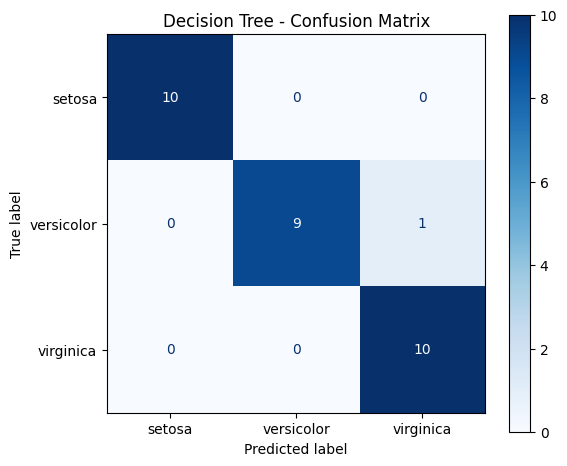

In [8]:
# 绘制测试集混淆矩阵
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1, 2],
    display_labels=iris.target_names,
    cmap="Blues",
    ax=ax
)
ax.set_title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. 决策树结构可视化

从根节点开始，如果样本满足节点的划分条件，则沿左分支继续判断，否则沿右分支继续判断，直到叶节点输出预测类别。

图中 `gini` 表示基尼不纯度，`samples` 表示训练样本数，`value` 表示各类别的样本分布，`class` 表示该节点的多数类别。

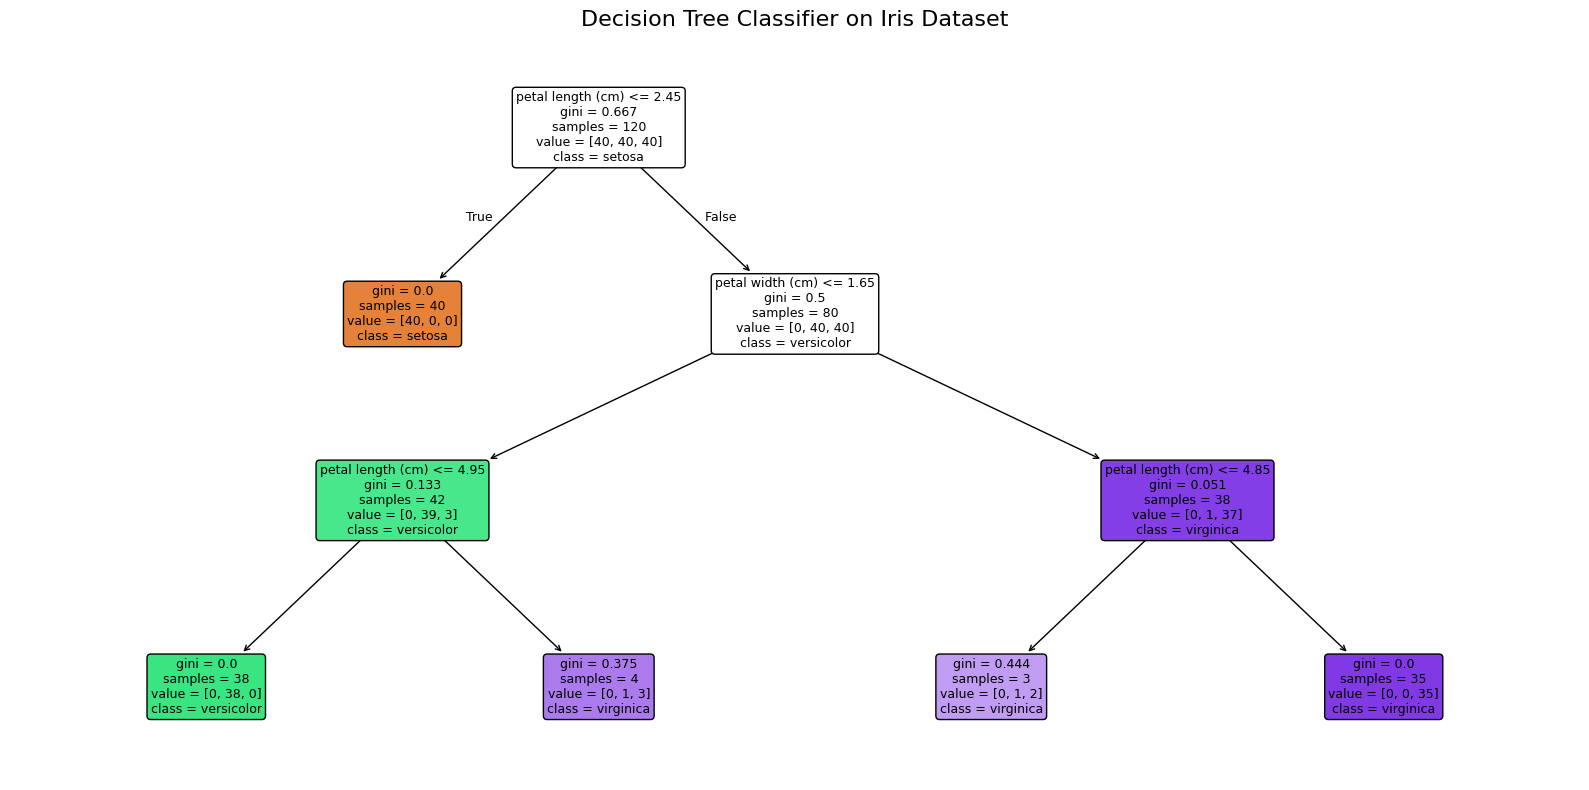

In [9]:
# 绘制训练完成的决策树，观察模型学到的划分规则
plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=iris.feature_names,  # 特征名称
    class_names=iris.target_names.tolist(),  # 类别名称
    filled=True,  # 根据类别和纯度填充颜色
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Classifier on Iris Dataset", fontsize=16)
plt.tight_layout()
plt.show()

## 8. 特征重要性分析

决策树的特征重要性反映各特征对降低不纯度的相对贡献。值越大，表示该特征在这棵树的划分过程中贡献越大。

特征重要性：
petal length (cm)    0.5791
petal width (cm)     0.4209
sepal width (cm)     0.0000
sepal length (cm)    0.0000
dtype: float64


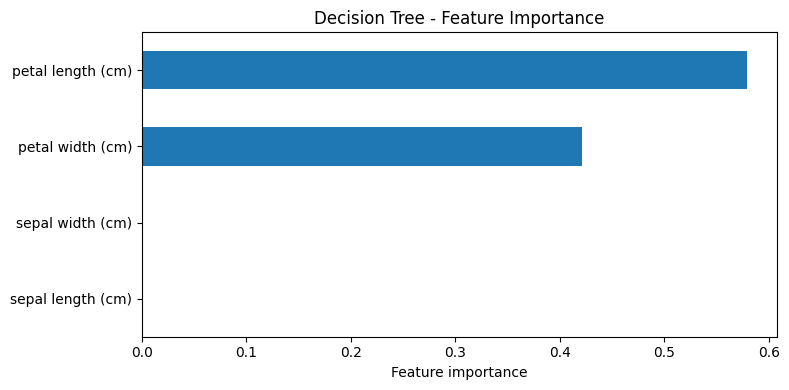

In [10]:
# 获取并排序模型的特征重要性
importance = pd.Series(model.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
print("特征重要性：")
print(importance.round(4))

# 使用横向条形图展示各特征的重要性
importance.sort_values().plot(kind="barh", figsize=(8, 4))
plt.xlabel("Feature importance")
plt.title("Decision Tree - Feature Importance")
plt.tight_layout()
plt.show()

## 9. 实验结论

本作业使用 Iris 数据集的 120 条训练样本，拟合了一个最大深度为 3 的决策树分类模型，并在 30 条独立测试样本上进行了评估。

- 训练集准确率为 **98.33%**，测试集准确率为 **96.67%**，模型在此次划分中表现出较好的分类能力。
- 通过决策树结构图和特征重要性图可以发现，花瓣相关特征在本模型中对分类起到了主要作用。
- 决策树具有直观、可解释的优点，但树的复杂度过高时可能出现过拟合。